# **Exploring Modularity in the Karate Club Network**
DSC212: Graph Theory Module

In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# Load the Karate Club network, which represents the friendship ties
# observed by Zachary. We will use modularity to examine how the
# network can be divided into distinct communities.
G = nx.karate_club_graph()

pos = nx.spring_layout(G, seed=42)


# Begin by constructing the modularity matrix: B = A - kk^T/(2m)

# Obtain the adjacency matrix of the graph
A = nx.to_numpy_array(G, weight=None)

# Calculate the degree of each node
k = np.zeros(34)
for i in range(34):
  k[i] = np.sum(A[i,:])
M = k.sum()

# Construct the modularity matrix
B = np.zeros((34,34))
for i in range(34):
  for j in range(34):
       B[i,j] = A[i,j] - (k[i]*k[j])/(M)


#----------------------------------------------------------------

## <u>Methodology</u>

The modularity framework, modularity matrix and spectral bisection approach used here are based on **Newman (2006)**, *"Modularity and community structure in networks,"* PNAS 103(23):8577–8582.

### 1. Network data
- The network is created with `nx.karate_club_graph()`. It contains 34 nodes and 78 edges, and is treated as an unweighted graph (`weight=None`).
- A spring layout with a fixed seed (`seed=42`) is applied to all figures to keep node positions consistent throughout the analysis.

### 2. Constructing the modularity matrix
- $A$ denotes the adjacency matrix, while $k_i = \sum_j A_{ij}$ represents the degree of node $i$. The total degree is $2m = \sum_i k_i = 156$.
- The modularity matrix is defined as

$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m}$$

  This expression measures the difference between the observed connections and the connections expected in a random network with the same node degrees.

### 3. Dividing a community
- For a community $C$, form the corresponding block $B^{(C)}$ by selecting from the original matrix the rows and columns associated with nodes in $C$.
- Use `np.linalg.eigh` to obtain the largest eigenvalue, $\lambda_1$, and its corresponding eigenvector, $u_1$.
- Assign nodes with $(u_1)_i > 0$ to one subgroup and all remaining nodes to the other.

### 4. Repeated community division
- Initially, all 34 nodes belong to a single community (level 0).
- **Terminate the division** when $\lambda_1 \le 0$, indicating that the proposed split does not improve modularity, or when the split produces an empty subgroup.
- If neither condition is met, divide the community and apply the same procedure to both resulting groups at the next level.
- The implementation uses the $\lambda_1 > 0$ condition on the unmodified block of $B$ (Section 3.3 of the handout), rather than Newman's corrected approach, which modifies the block's diagonal entries.

### 5. Bisection levels
- Each *level* represents one stage in the recursive division process.
- Communities that cannot be divided further are retained at subsequent levels. Consequently, each level continues to include all 34 nodes.
- The procedure produces four levels (0–3), ending with five communities.

### 6. Node-level measures
- At every level, the analysis calculates degree, betweenness and closeness centrality, along with the clustering coefficient using NetworkX.
- These measures are evaluated on a graph containing all 34 nodes but retaining only edges whose endpoints belong to the same community. Connections between different communities are removed.
- The normalisation based on the complete 34-node graph is maintained at every level, allowing the results to be compared directly.
- The values are saved in the structure `metric[level][metric_name][node]`.

### 7. Network plots and metric trends
- A distinct colour is assigned whenever a new community appears. If a community remains unchanged, it retains its colour at the next level.
- The metric evolution figures trace each node across the levels, while nine selected nodes are highlighted for easier comparison.

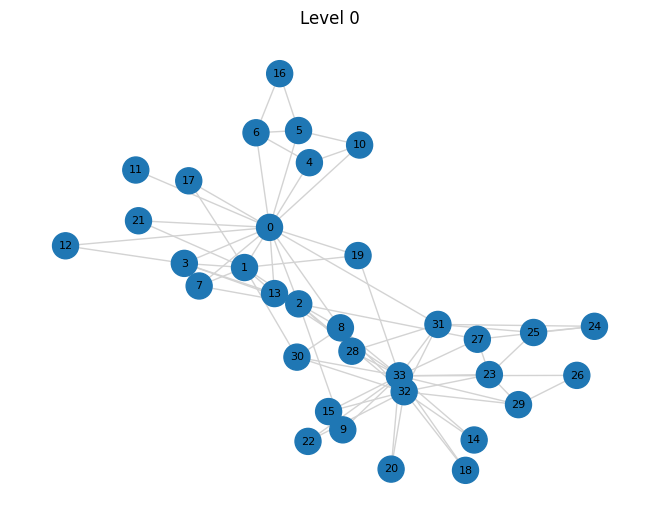

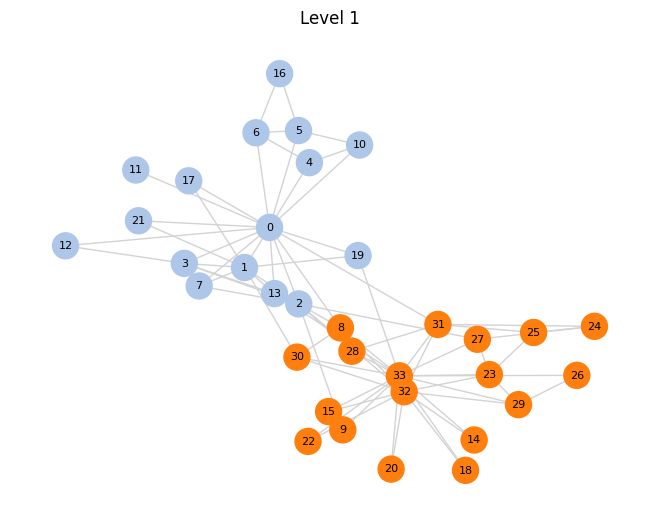

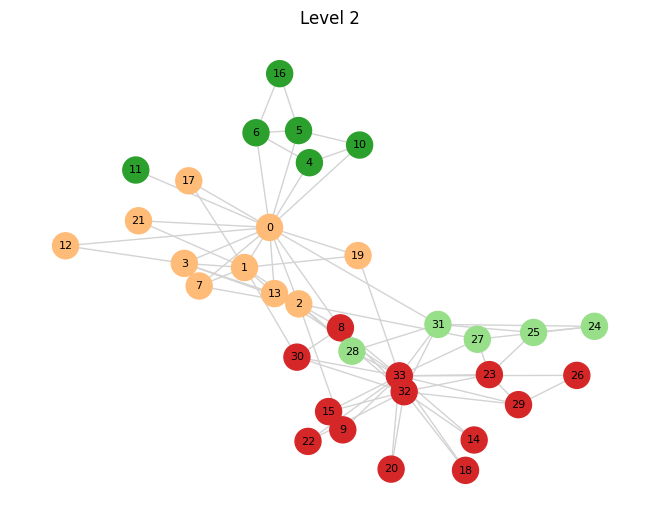

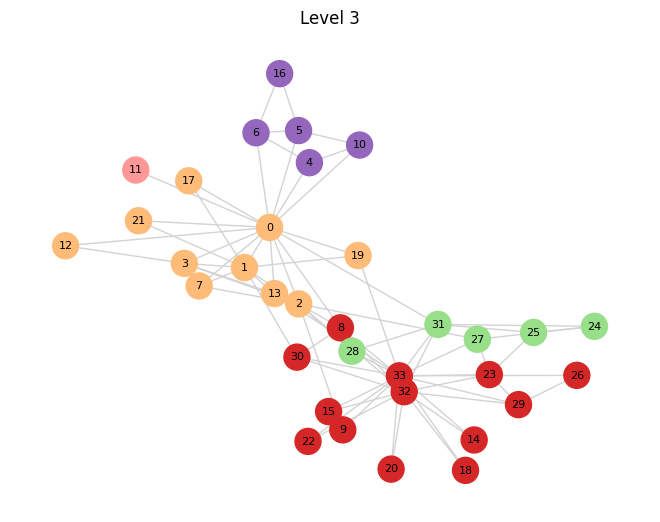

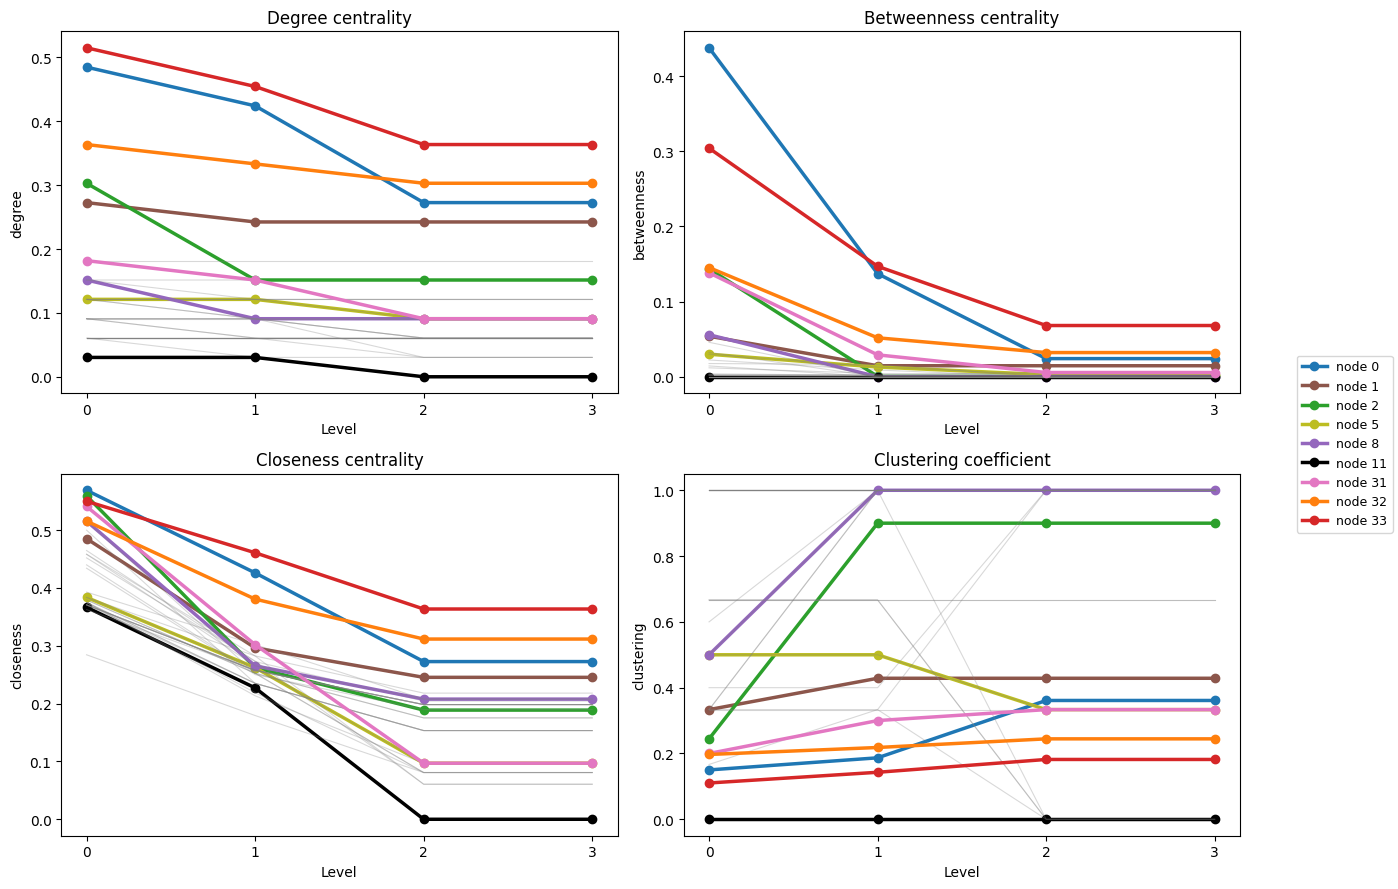

In [ ]:



# This function builds the modularity matrix for a selected community
# and returns its leading eigenvector and eigenvalue.



def modularity_matrix(community):
    B_c = np.zeros((len(community),len(community)))
    for i in range(len(community)):
         for j in range(len(community)):
            p = community[i]
            q = community[j]
            B_c[i][j] = A[p][q] - (k[p]*k[q])/M
    u_c, V_c = np.linalg.eigh(B_c)
    u1_c = V_c[:, -1]
    u_max_c = u_c[-1]
    return u1_c,u_max_c

def eigen_test(u_max_c):
    if u_max_c > 0:
        return True
    else:
        return False

def split(community,u1_c):
        s_c = np.zeros(len(community))
        for i in range(len(community)):
            s_c[i] = 1 if u1_c[i] > 0 else -1
        comm1 = []
        comm2 = []
        for i in range(len(community)):
            if s_c[i] == 1:
                comm1 = comm1 + [community[i]]
            else:
                comm2 = comm2 + [community[i]]
        comm = [comm1,comm2]
        return comm

# Store communities by level so that measures can be calculated consistently.
levels = {}

def recursive_thing(community, level):

    if level not in levels:
        levels[level] = []
    levels[level].append(community)

    u1_c, u_max_c = modularity_matrix(community)
    if eigen_test(u_max_c) is False:
        return [community]

# Prevent further recursion if the division produces an empty group.

    comm1, comm2 = split(community, u1_c)
    if len(comm1) == 0 or len(comm2) == 0:
        return [community]


    return recursive_thing(comm1, level + 1) + recursive_thing(comm2, level + 1)


G_nodes = []
for node in G.nodes:
    G_nodes = G_nodes + [node]

final = recursive_thing(G_nodes, 0)

# The recursion identifies the communities that can no longer be divided.
# These unchanged communities are then carried forward to later levels.

for L in range(1, len(levels)):
    for c in levels[L - 1]:
        if c in final:
            levels[L].append(c)
# Calculate the network measures at each level.
metric = {}
for L in levels:
    H = nx.Graph()
    for c in levels[L]:
        H = nx.compose(H, G.subgraph(c))
    metric[L] = {'degree':      nx.degree_centrality(H),
                 'betweenness': nx.betweenness_centrality(H),
                 'closeness':   nx.closeness_centrality(H),
                 'clustering':  nx.clustering(H)}



# Assign a separate colour to each community.

# Use a colormap to distinguish communities; first assign each one an identifier.

# Assign identifiers to newly formed communities.
cmap = plt.get_cmap('tab20')
unq_num = {}
num = 0

for L in levels:
    for c in levels[L]:
        key = tuple(c)
        if L > 0 and c in levels[L - 1]:
            pass
        else:
            unq_num[key] = num
            num = num + 1

# Draw the network using the community colours.

for L in levels:
    colors = [0] * 34
    for c in levels[L]:
        for node in c:
            colors[node] = cmap(unq_num[tuple(c)])

    nx.draw(G, pos, with_labels=True, node_color=colors,
            node_size=350, font_size=8, edge_color='lightgray')
    plt.title(f"Level {L}")
    plt.show()

# Plot how the selected node measures change across levels.

names = ['degree', 'betweenness', 'closeness', 'clustering']
titles = ['Degree centrality', 'Betweenness centrality',
          'Closeness centrality', 'Clustering coefficient']

key_nodes  = [0, 33, 32, 2, 8, 1, 31, 11, 5]
key_colors = ['tab:blue', 'tab:red', 'tab:orange', 'tab:green', 'tab:purple',
              'tab:brown', 'tab:pink', 'black', 'tab:olive']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for index in range(4):
    ax = axes[index // 2][index % 2]
    name = names[index]

    for node in G.nodes:
        values = [metric[L][name][node] for L in levels]
        if node in key_nodes:
            ax.plot(list(levels), values, color=key_colors[key_nodes.index(node)],
                    linewidth=2.5, marker='o', label=f'node {node}')
        else:
            ax.plot(list(levels), values, color='gray', linewidth=0.8, alpha=0.3)

    ax.set_title(titles[index])
    ax.set_xlabel('Level')
    ax.set_ylabel(name)
    ax.set_xticks(list(levels))


handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center right', fontsize=9)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

# Grey lines represent the remaining nodes and keep the plots readable.

## <u>Discussion</u>

### Nodes that retain their central positions

Nodes **33**, **0** and **32** continue to be among the most central throughout the division process. Before the network is split, these nodes appear in the top five for degree, betweenness and closeness centrality. After the first division, they remain within the top three at each level. Node 33 has the greatest degree centrality at every stage (0.52 → 0.45 → 0.36 → 0.36). Initially, node 0 (the instructor, Mr Hi) has the highest betweenness (0.44) and closeness (0.57).

In Zachary's account, nodes 0 and 33 lead the two opposing groups. The first division places them in separate communities: node 0 is grouped with 15 other nodes, while node 33 is grouped with 17. This division agrees with the club's actual split for 33 of its 34 members. The exception is node 8, which the algorithm places with John A's group even though the member ultimately remained with Mr Hi.

Their central positions persist because a large share of their connections lie within their respective communities. Removing links between communities therefore eliminates relatively few of their connections, allowing them to remain important nodes within their groups.

### The influence of community divisions on network measures

Following each division, the measures are calculated on the full network of 34 nodes after removing edges that connect different communities. The first division removes 10 edges, and the second removes a further 11. The resulting values therefore indicate how each node's structural importance changes when connections are restricted to its own community.

- **Betweenness experiences the sharpest decline.** Before division, several shortest paths connecting the two factions pass through a small number of nodes. Node 0's betweenness decreases from 0.44 to 0.14 after the first division, and then to 0.02 after the second. The values for nodes 2 and 8 also fall from 0.14 and 0.06 to zero. Their earlier scores reflected their role in connecting the two factions, a role that disappears when those links are removed.
- **Degree and closeness decrease when many external links are removed.** Node 2 loses half of its degree in the first division (0.30 → 0.15), causing it to fall outside the top five. By contrast, node 1 changes only slightly (0.27 → 0.24), since nearly all of its connections remain within its own community. As a result, node 1 moves higher in the ranking.
- **Clustering generally becomes greater.** After the split, a node's remaining neighbours tend to belong to its closely connected group and are more likely to be connected to one another. For example, node 2's clustering coefficient rises from 0.24 to 0.90, while node 8's increases from 0.50 to 1.00.
- **Node 11** is connected to only one other node, node 0. At level 2, they belong to different communities. Once their connecting edge is removed, node 11 has no remaining edges, and all of its measures become zero.

### Comparing levels 2 and 3

The metric values at levels 2 and 3 are exactly the same. At level 3, the only additional division separates node 11 from its community. Since node 11 has no edges within that group, this step removes no further edges and therefore leaves every metric unchanged. Modularity increases only slightly, from Q = 0.408 to Q = 0.409, compared with the value of 0.372 after the first division.

This outcome illustrates a weakness of applying the simple $\lambda > 0$ condition to a block of $B$: the method may separate a node that is already disconnected from the rest of its community. Newman's corrected method (2006), which adjusts the diagonal of the block matrix, would not produce this additional division.

### Conclusion

The community structure affects different centrality measures in different ways. Nodes whose importance comes from **connecting separate communities**—such as nodes 2 and 8, and node 0 in terms of betweenness—lose that function when the links between groups are removed. In contrast, nodes that act as **hubs within their own communities**, including nodes 33, 0, 32 and 1, largely preserve their central positions. The clustering coefficient tends to increase because the remaining neighbourhoods become more internally connected.

**Reference**

Newman, M. E. J. (2006). Modularity and community structure in networks. Proceedings of the National Academy of Sciences, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103

**AI Use Statement**

Claude was used to assist with three implementation tasks: adding a level parameter to the recursive function to organise communities by level, assigning colours to communities in the network diagrams, and creating the plots that show how the node metrics change across levels.